# EARTHSC 5201: Introduction to Seismology

## Homework 3

**Seyhmus Tunc**
The Ohio State University
Autumn 2026

# Problem 1

On February 3, 2025, an $M$ 3.1 earthquake occurred near Oak Hill, Ohio (USGS event ID `se60597816`). The published hypocenter is used throughout this problem:

- Origin time: February 3, 2025 at 21:04:52.85 UTC
- Latitude: $38.920^\circ$ N
- Longitude: $82.581^\circ$ W
- Depth: 25.9 km

The vertical-component waveforms from six nearby stations (N4.Q51A, N4.Q52A, OH.CHWO, OH.CPOH, OH.DSFO, and OH.SSF2) are used to pick the P-wave arrivals, estimate a P-wave velocity, relocate the earthquake, and estimate the earthquake early warning time for Mendenhall Laboratory.

In [1]:
!pip install obspy geopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 43.8 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt

import geopy.distance

from obspy import UTCDateTime
from obspy.clients.fdsn import Client
from obspy.taup import TauPyModel
from obspy.geodetics.base import gps2dist_azimuth, kilometer2degrees

### Given Parameters

In [3]:
# Published hypocenter (USGS se60597816)
origin_time = UTCDateTime("2025-02-03T21:04:52.85")

event_lat = 38.920
event_lon = -82.581
event_depth = 25.9  # km

# Stations used in this problem
station_names = [
    "N4.Q51A",
    "N4.Q52A",
    "OH.CHWO",
    "OH.CPOH",
    "OH.DSFO",
    "OH.SSF2",
]

# Problem 1A

### Retrieving the Waveforms

The vertical-component broadband (HHZ) waveforms are downloaded from EarthScope (formerly IRIS) starting 10 s before the origin time and ending 40 s after it. The station coordinates are retrieved at the same time.

In [4]:
client = Client("EARTHSCOPE")

waveforms = {}
station_coords = {}

for name in station_names:

    net, sta = name.split(".")

    st = client.get_waveforms(
        network=net,
        station=sta,
        location="*",
        channel="HHZ",
        starttime=origin_time - 10,
        endtime=origin_time + 40
    )

    inv = client.get_stations(
        network=net,
        station=sta,
        channel="HHZ",
        starttime=origin_time,
        endtime=origin_time + 40,
        level="station"
    )

    waveforms[name] = st[0]
    station_coords[name] = (
        inv[0][0].latitude,
        inv[0][0].longitude
    )

for name in station_names:
    tr = waveforms[name]
    lat, lon = station_coords[name]
    print(
        f"{tr.id:18s} "
        f"Lat = {lat:8.4f}, "
        f"Lon = {lon:9.4f}, "
        f"{tr.stats.sampling_rate:5.0f} Hz"
    )

N4.Q51A.00.HHZ     Lat =  39.0260, Lon =  -83.3456,   100 Hz
N4.Q52A.00.HHZ     Lat =  38.9622, Lon =  -82.2669,   100 Hz
OH.CHWO..HHZ       Lat =  38.9360, Lon =  -82.5261,   100 Hz
OH.CPOH..HHZ       Lat =  38.8401, Lon =  -83.5776,   100 Hz
OH.DSFO.10.HHZ     Lat =  38.6910, Lon =  -82.6169,   200 Hz
OH.SSF2..HHZ       Lat =  38.6886, Lon =  -83.1276,   100 Hz


### Waveform Processing

The mean is removed from each trace, and time is measured in seconds after the published origin time. The full 30 s records are plotted first to see where the P and S waves arrive at each station.

In [5]:
def time_after_origin(tr):
    return tr.times() + (tr.stats.starttime - origin_time)


for name in station_names:
    waveforms[name].detrend("demean")

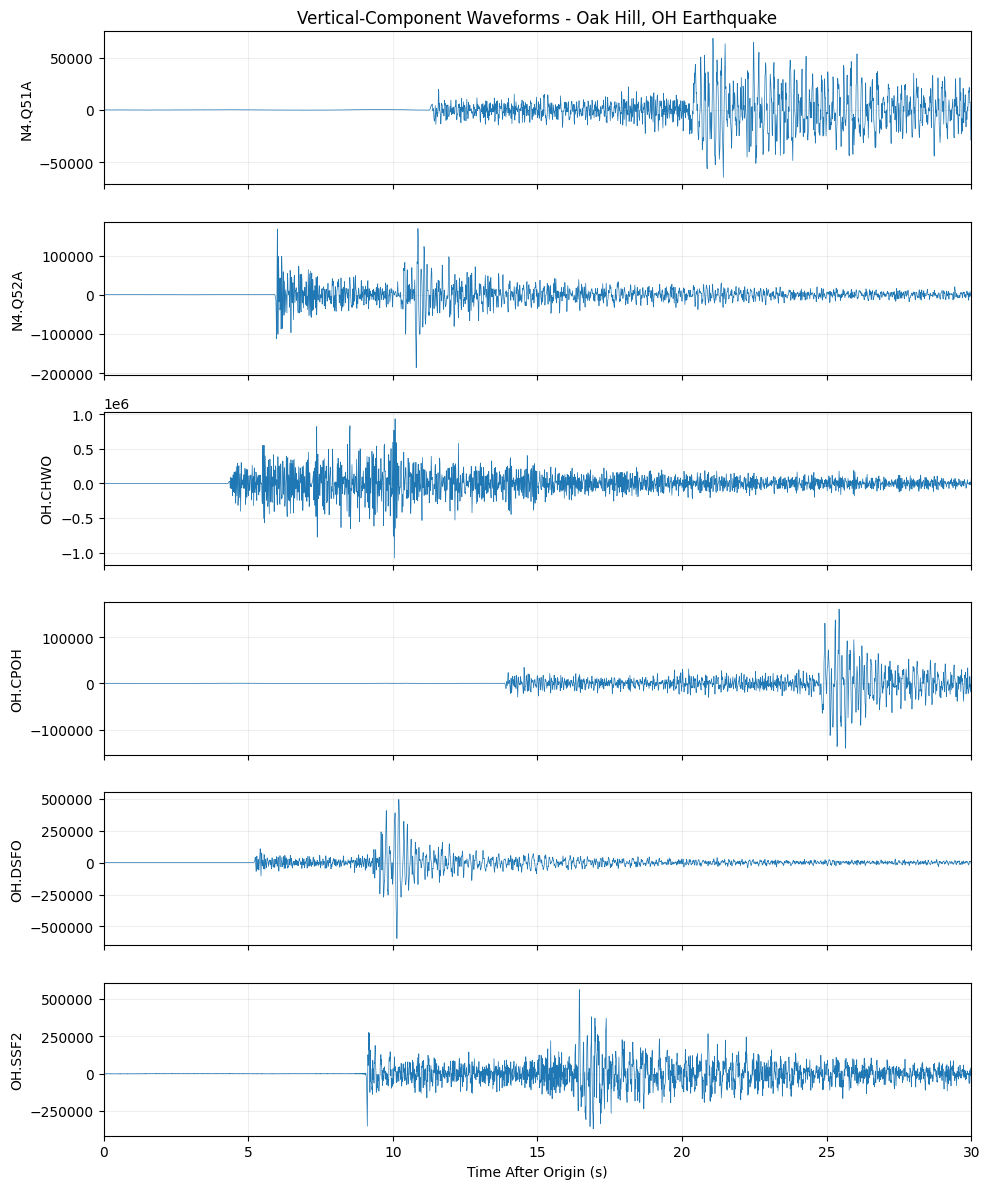

In [6]:
fig, axes = plt.subplots(len(station_names), 1, figsize=(10, 12), sharex=True)

for ax, name in zip(axes, station_names):

    tr = waveforms[name]
    t = time_after_origin(tr)

    ax.plot(t, tr.data, linewidth=0.5)
    ax.set_ylabel(name)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time After Origin (s)")
axes[-1].set_xlim(0, 30)
axes[0].set_title("Vertical-Component Waveforms - Oak Hill, OH Earthquake")

plt.tight_layout()
plt.show()

### Manual P-Wave Picks

Each record is zoomed into a 1 s window around the first P-wave motion, and the arrival is picked as the time where the trace first departs from the pre-event noise. Since the records are sampled at 100-200 Hz, the onsets can be read to about 0.01 s, which is more precise than the required 0.1 s. Rounding to 0.1 s would shift some picks by up to 0.07 s after the actual onset.

In [7]:
# Manually picked P-wave arrivals (seconds after origin time)
p_picks = {
    "N4.Q51A": 11.27,
    "N4.Q52A": 5.92,
    "OH.CHWO": 4.29,
    "OH.CPOH": 13.84,
    "OH.DSFO": 5.18,
    "OH.SSF2": 9.07,
}

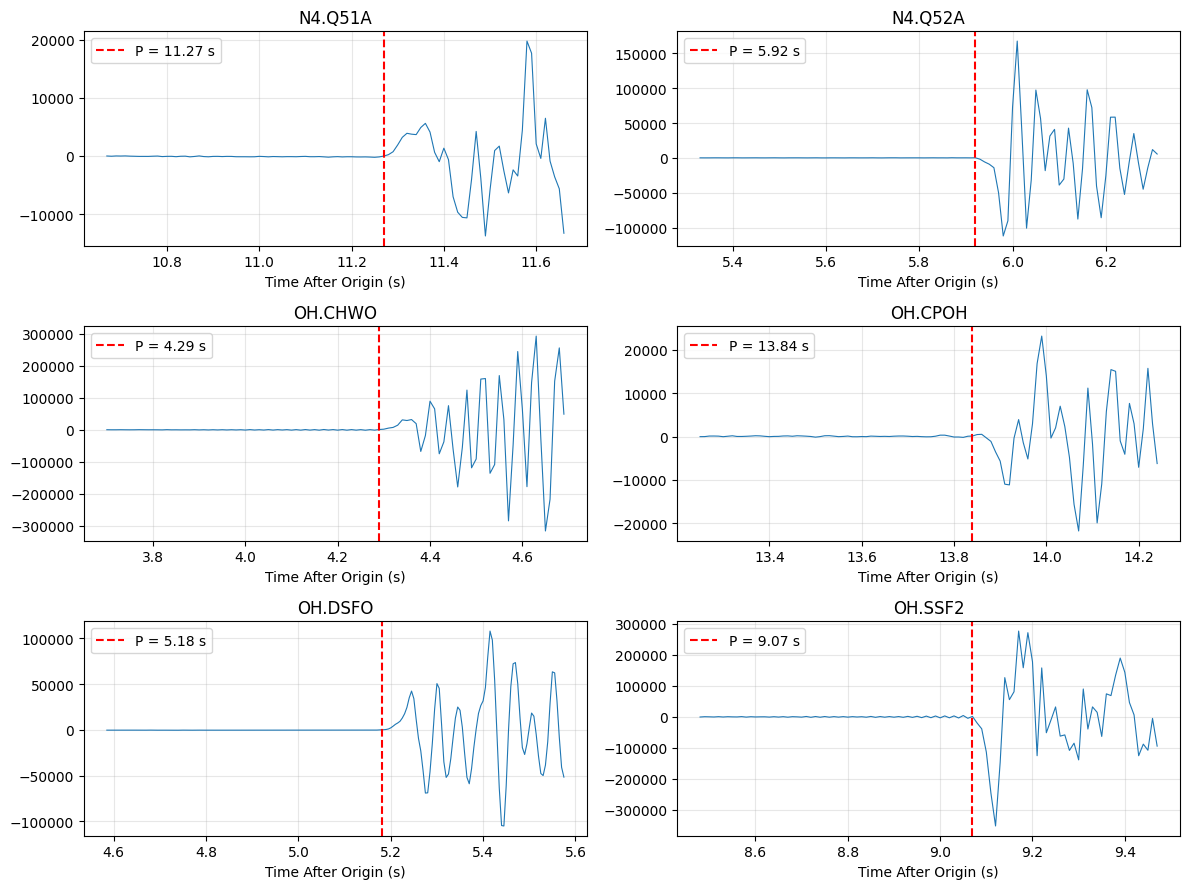

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))

for ax, name in zip(axes.flatten(), station_names):

    tr = waveforms[name]
    t = time_after_origin(tr)

    pick = p_picks[name]
    window = (t > pick - 0.6) & (t < pick + 0.4)

    ax.plot(t[window], tr.data[window], linewidth=0.8)
    ax.axvline(pick, color="red", linestyle="--", label=f"P = {pick:.2f} s")

    ax.set_title(name)
    ax.set_xlabel("Time After Origin (s)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [9]:
for name in station_names:
    print(f"{name:8s}  P arrival = {p_picks[name]:5.2f} s")

N4.Q51A   P arrival = 11.27 s
N4.Q52A   P arrival =  5.92 s
OH.CHWO   P arrival =  4.29 s
OH.CPOH   P arrival = 13.84 s
OH.DSFO   P arrival =  5.18 s
OH.SSF2   P arrival =  9.07 s


# Problem 1B

### Hypocentral Distances

The epicentral distance between the published epicenter and each station is calculated using `geopy.distance.distance`. Since the earthquake is 25.9 km deep, the hypocentral distance is

$$
r = \sqrt{\Delta^2 + h^2},
$$

where $\Delta$ is the epicentral distance and $h$ is the depth.

In [10]:
epi_dist = []
hypo_dist = []
t_obs = []

for name in station_names:

    coord1 = (event_lat, event_lon)
    coord2 = station_coords[name]

    epidist = geopy.distance.distance(coord1, coord2).km
    hypodist = np.sqrt(epidist**2 + event_depth**2)

    epi_dist.append(epidist)
    hypo_dist.append(hypodist)
    t_obs.append(p_picks[name])

epi_dist = np.array(epi_dist)
hypo_dist = np.array(hypo_dist)
t_obs = np.array(t_obs)

for i, name in enumerate(station_names):
    print(
        f"{name:8s} "
        f"Epicentral = {epi_dist[i]:6.2f} km, "
        f"Hypocentral = {hypo_dist[i]:6.2f} km, "
        f"P = {t_obs[i]:5.2f} s"
    )

N4.Q51A  Epicentral =  67.30 km, Hypocentral =  72.11 km, P = 11.27 s
N4.Q52A  Epicentral =  27.63 km, Hypocentral =  37.87 km, P =  5.92 s
OH.CHWO  Epicentral =   5.08 km, Hypocentral =  26.39 km, P =  4.29 s
OH.CPOH  Epicentral =  86.93 km, Hypocentral =  90.71 km, P = 13.84 s
OH.DSFO  Epicentral =  25.62 km, Hypocentral =  36.43 km, P =  5.18 s
OH.SSF2  Epicentral =  53.98 km, Hypocentral =  59.88 km, P =  9.07 s


### Best-Fitting P-Wave Velocity

Assuming a straight ray path with a constant velocity, the P-wave travel time is

$$
t_i = \frac{r_i}{\alpha}.
$$

Since the origin time is fixed at the published value, the only unknown is the velocity. Writing the travel time in terms of the slowness $u = 1/\alpha$, the problem becomes linear:

$$
t_i = u\, r_i.
$$

The L2 misfit is

$$
E = \sum_i \left(t_i - u\, r_i\right)^2,
$$

and setting $dE/du = 0$ gives the least-squares slowness

$$
u = \frac{\sum_i r_i t_i}{\sum_i r_i^2},
\qquad
\alpha = \frac{1}{u}.
$$

In [11]:
# Least-squares slowness and velocity
u_best = np.sum(hypo_dist * t_obs) / np.sum(hypo_dist**2)
alpha_best = 1.0 / u_best

# Residuals
t_pred = hypo_dist / alpha_best
residuals = t_obs - t_pred
rms = np.sqrt(np.mean(residuals**2))

print(f"Best-fitting P-wave velocity = {alpha_best:.2f} km/s")
print(f"RMS residual = {rms:.3f} s\n")

for i, name in enumerate(station_names):
    print(
        f"{name:8s} "
        f"Observed = {t_obs[i]:5.2f} s, "
        f"Predicted = {t_pred[i]:5.2f} s, "
        f"Residual = {residuals[i]:6.2f} s"
    )

Best-fitting P-wave velocity = 6.52 km/s
RMS residual = 0.223 s

N4.Q51A  Observed = 11.27 s, Predicted = 11.05 s, Residual =   0.22 s
N4.Q52A  Observed =  5.92 s, Predicted =  5.80 s, Residual =   0.12 s
OH.CHWO  Observed =  4.29 s, Predicted =  4.05 s, Residual =   0.24 s
OH.CPOH  Observed = 13.84 s, Predicted = 13.90 s, Residual =  -0.06 s
OH.DSFO  Observed =  5.18 s, Predicted =  5.58 s, Residual =  -0.40 s
OH.SSF2  Observed =  9.07 s, Predicted =  9.18 s, Residual =  -0.11 s


### Velocity Grid Search

As a check, the RMS misfit is also calculated for velocities from 4 to 9 km/s. The minimum of the misfit curve should agree with the least-squares solution above.

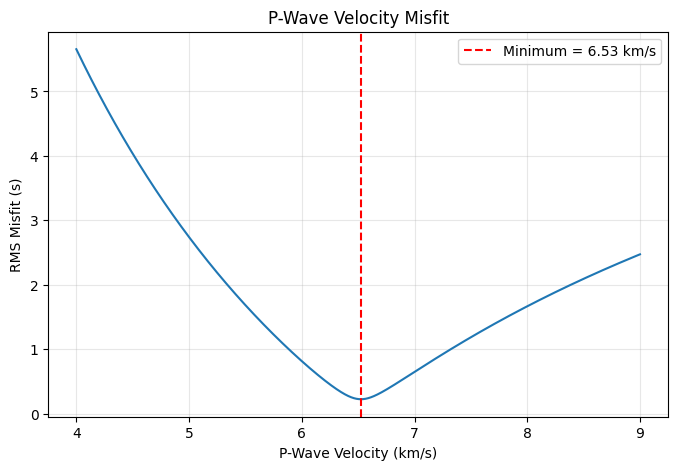

In [12]:
velocities = np.arange(4.0, 9.0 + 0.001, 0.001)

rms_v = np.array([
    np.sqrt(np.mean((t_obs - hypo_dist / v)**2))
    for v in velocities
])

v_grid = velocities[np.argmin(rms_v)]

plt.figure(figsize=(8, 5))

plt.plot(velocities, rms_v)
plt.axvline(v_grid, color="red", linestyle="--", label=f"Minimum = {v_grid:.2f} km/s")

plt.xlabel("P-Wave Velocity (km/s)")
plt.ylabel("RMS Misfit (s)")
plt.title("P-Wave Velocity Misfit")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

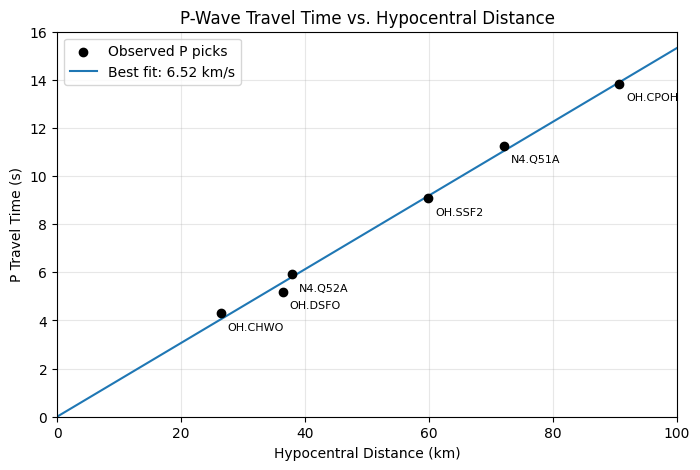

In [13]:
r_line = np.linspace(0, 100, 200)

plt.figure(figsize=(8, 5))

plt.scatter(hypo_dist, t_obs, color="black", zorder=3, label="Observed P picks")
plt.plot(r_line, r_line / alpha_best, label=f"Best fit: {alpha_best:.2f} km/s")

for i, name in enumerate(station_names):
    plt.annotate(name, (hypo_dist[i], t_obs[i]),
                 textcoords="offset points", xytext=(5, -12), fontsize=8)

plt.xlabel("Hypocentral Distance (km)")
plt.ylabel("P Travel Time (s)")
plt.title("P-Wave Travel Time vs. Hypocentral Distance")
plt.xlim(0, 100)
plt.ylim(0, 16)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

### Observation

A single P-wave velocity of about 6.52 km/s fits the six P-wave picks with an RMS residual of about 0.22 s. This value is between the upper-crust (5.8 km/s) and lower-crust (6.5 km/s) P velocities of the ak135 model, which is reasonable since the rays from a 25.9 km deep source travel mostly through the middle and lower crust before reaching the stations.

# Problem 1C

### Grid-Search Location with ak135

The earthquake is relocated by a grid search around the published epicenter. The grid extends $\pm0.5^\circ$ in both latitude and longitude with a spacing of $0.01^\circ$, while the depth is held fixed at 25.9 km.

At each grid point, the theoretical P travel time to every station is calculated using the ak135 model. Since the source is in the crust and the stations are within ~90 km, the direct upgoing **`p`** phase is used.

For a trial epicenter, the predicted arrival time at station $i$ is

$$
t_i^{\text{pred}} = t_0 + \delta t + T_i(\text{lat},\text{lon}),
$$

where $T_i$ is the ak135 travel time and $\delta t$ is the origin time difference relative to the published origin time. For the L2 norm, the best origin time difference at each grid point is the mean residual,

$$
\delta t = \frac{1}{N}\sum_i \left(t_i^{\text{obs}} - T_i\right),
$$

and the misfit is

$$
E = \sqrt{\frac{1}{N}\sum_i \left(t_i^{\text{obs}} - T_i - \delta t\right)^2}.
$$

In [14]:
model = TauPyModel(model="ak135")

### Travel-Time Table

Calling TauP for every grid point and station would require more than 60,000 calls. Since the depth is fixed, the `p` travel time only depends on the epicentral distance. Therefore, TauP is used to build a travel-time table every $0.002^\circ$ from $0^\circ$ to $2^\circ$, and the travel time at any distance is interpolated from this table.

In [15]:
table_dist = np.arange(0.0, 2.0 + 0.002, 0.002)
table_time = np.zeros_like(table_dist)

for i, dist in enumerate(table_dist):

    arrivals = model.get_travel_times(
        source_depth_in_km=event_depth,
        distance_in_degree=dist,
        phase_list=["p"]
    )

    table_time[i] = arrivals[0].time


def p_travel_time(dist_deg):
    return np.interp(dist_deg, table_dist, table_time)

In [16]:
# Check the table against a direct TauP call
test_dist = 0.5

arrivals = model.get_travel_times(
    source_depth_in_km=event_depth,
    distance_in_degree=test_dist,
    phase_list=["p"]
)

print(f"TauP p time at {test_dist} deg = {arrivals[0].time:.3f} s")
print(f"Interpolated p time          = {p_travel_time(test_dist):.3f} s")

TauP p time at 0.5 deg = 10.226 s
Interpolated p time          = 10.226 s


### Grid Search

The distance between each grid point and each station is calculated using `gps2dist_azimuth`, which returns the distance in meters. The distance is converted to degrees before the travel time is calculated.

In [17]:
lat_grid = np.round(np.arange(event_lat - 0.5, event_lat + 0.5 + 0.001, 0.01), 3)
lon_grid = np.round(np.arange(event_lon - 0.5, event_lon + 0.5 + 0.001, 0.01), 3)

misfit = np.zeros((len(lat_grid), len(lon_grid)))
dt_grid = np.zeros((len(lat_grid), len(lon_grid)))

for i, lat in enumerate(lat_grid):
    for j, lon in enumerate(lon_grid):

        T = np.zeros(len(station_names))

        for k, name in enumerate(station_names):

            sta_lat, sta_lon = station_coords[name]

            dist_m, _, _ = gps2dist_azimuth(lat, lon, sta_lat, sta_lon)
            dist_deg = kilometer2degrees(dist_m / 1000.0)

            T[k] = p_travel_time(dist_deg)

        res = t_obs - T
        dt = np.mean(res)

        dt_grid[i, j] = dt
        misfit[i, j] = np.sqrt(np.mean((res - dt)**2))

print(f"Grid size = {len(lat_grid)} x {len(lon_grid)}")

Grid size = 101 x 101


In [18]:
# Best location
i_best, j_best = np.unravel_index(np.argmin(misfit), misfit.shape)

best_lat = lat_grid[i_best]
best_lon = lon_grid[j_best]
best_dt = dt_grid[i_best, j_best]
best_misfit = misfit[i_best, j_best]

best_origin = origin_time + best_dt

shift_km = geopy.distance.distance(
    (event_lat, event_lon),
    (best_lat, best_lon)
).km

print(f"Best latitude          = {best_lat:.2f} deg")
print(f"Best longitude         = {best_lon:.2f} deg")
print(f"Origin time difference = {best_dt:+.2f} s")
print(f"Best origin time       = {best_origin}")
print(f"RMS misfit             = {best_misfit:.3f} s")
print(f"Distance from published epicenter = {shift_km:.2f} km")

Best latitude          = 38.89 deg
Best longitude         = -82.60 deg
Origin time difference = -0.56 s
Best origin time       = 2025-02-03T21:04:52.286201Z
RMS misfit             = 0.172 s
Distance from published epicenter = 3.76 km


### Misfit Space

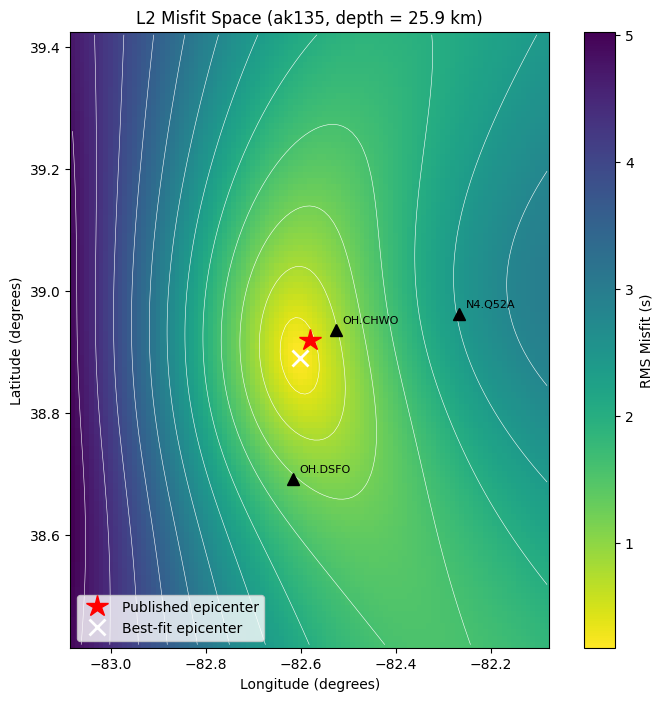

In [19]:
fig, ax = plt.subplots(figsize=(9, 8))

pc = ax.pcolormesh(lon_grid, lat_grid, misfit, cmap="viridis_r", shading="auto")
ax.contour(lon_grid, lat_grid, misfit, levels=15, colors="white", linewidths=0.4)

fig.colorbar(pc, ax=ax, label="RMS Misfit (s)")

ax.plot(event_lon, event_lat, "r*", markersize=16, label="Published epicenter")
ax.plot(best_lon, best_lat, "wx", markersize=12, markeredgewidth=2, label="Best-fit epicenter")

for name in station_names:
    sta_lat, sta_lon = station_coords[name]
    if (lat_grid[0] <= sta_lat <= lat_grid[-1]) and (lon_grid[0] <= sta_lon <= lon_grid[-1]):
        ax.plot(sta_lon, sta_lat, "k^", markersize=9)
        ax.annotate(name, (sta_lon, sta_lat), textcoords="offset points",
                    xytext=(5, 5), fontsize=8)

ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title("L2 Misfit Space (ak135, depth = 25.9 km)")
ax.set_aspect(1 / np.cos(np.radians(event_lat)))
ax.legend(loc="lower left")

plt.show()

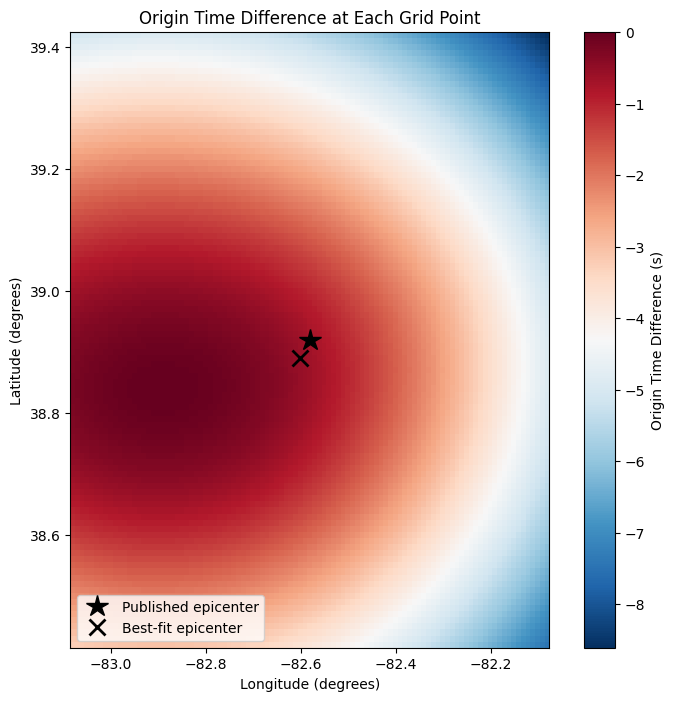

In [20]:
fig, ax = plt.subplots(figsize=(9, 8))

pc = ax.pcolormesh(lon_grid, lat_grid, dt_grid, cmap="RdBu_r", shading="auto")
fig.colorbar(pc, ax=ax, label="Origin Time Difference (s)")

ax.plot(event_lon, event_lat, "k*", markersize=16, label="Published epicenter")
ax.plot(best_lon, best_lat, "kx", markersize=12, markeredgewidth=2, label="Best-fit epicenter")

ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title("Origin Time Difference at Each Grid Point")
ax.set_aspect(1 / np.cos(np.radians(event_lat)))
ax.legend(loc="lower left")

plt.show()

In [21]:
# Residuals at the best location
print(f"{'Station':8s} {'Observed':>9s} {'Predicted':>10s} {'Residual':>9s}")

for name in station_names:

    sta_lat, sta_lon = station_coords[name]
    dist_m, _, _ = gps2dist_azimuth(best_lat, best_lon, sta_lat, sta_lon)
    T = p_travel_time(kilometer2degrees(dist_m / 1000.0))

    pred = T + best_dt
    print(f"{name:8s} {p_picks[name]:9.2f} {pred:10.2f} {p_picks[name] - pred:9.2f}")

Station   Observed  Predicted  Residual
N4.Q51A      11.27      11.26      0.01
N4.Q52A       5.92       6.09     -0.17
OH.CHWO       4.29       4.01      0.28
OH.CPOH      13.84      14.08     -0.24
OH.DSFO       5.18       5.16      0.02
OH.SSF2       9.07       8.97      0.10


### Observation

The minimum L2 misfit is found at $38.89^\circ$ N, $82.60^\circ$ W, about 3.8 km southwest of the published epicenter, with an origin time about 0.56 s earlier than the published origin time. The RMS misfit decreases from 0.22 s (constant velocity, published location) to 0.17 s.

The misfit space forms a valley that is elongated in the north-south direction rather than a circular minimum. This is expected because the six stations are spread mostly in the east-west direction (from about $83.6^\circ$ W to $82.3^\circ$ W), while they only cover a narrow latitude range ($38.69^\circ$ to $39.03^\circ$ N). As a result, the longitude of the epicenter is better constrained than its latitude. There is also a trade-off between the epicenter location and the origin time difference: moving the epicenter towards a group of stations can be partly compensated by shifting the origin time.

# Problem 1D

### Earthquake Early Warning at Mendenhall Laboratory

For earthquake early warning, the magnitude and origin time are estimated once 3 s of P-wave data are available at 4 stations. The four closest stations are selected below, and the alert time is

$$
t_{\text{alert}} = t_P^{(4)} + 3\ \text{s},
$$

where $t_P^{(4)}$ is the P arrival at the 4th station. The warning time at Mendenhall Laboratory is then

$$
t_{\text{warning}} = T_s^{\text{Mendenhall}} - t_{\text{alert}},
$$

where $T_s$ is the ak135 theoretical `s` travel time from the published hypocenter to Mendenhall Laboratory.

In [22]:
# Four closest stations
order = np.argsort(epi_dist)
closest = [station_names[i] for i in order[:4]]

for name in closest:
    i = station_names.index(name)
    print(f"{name:8s} Epicentral = {epi_dist[i]:6.2f} km, P = {p_picks[name]:5.2f} s")

OH.CHWO  Epicentral =   5.08 km, P =  4.29 s
OH.DSFO  Epicentral =  25.62 km, P =  5.18 s
N4.Q52A  Epicentral =  27.63 km, P =  5.92 s
OH.SSF2  Epicentral =  53.98 km, P =  9.07 s


In [23]:
# Time of the magnitude estimate
t_p4 = max(p_picks[name] for name in closest)
t_alert = t_p4 + 3.0

print(f"P arrival at the 4th station = {t_p4:.2f} s")
print(f"Alert time                   = {t_alert:.2f} s after origin")

P arrival at the 4th station = 9.07 s
Alert time                   = 12.07 s after origin


In [24]:
# Mendenhall Laboratory, The Ohio State University
mendenhall_lat = 39.9995
mendenhall_lon = -83.0126

dist_m, _, _ = gps2dist_azimuth(event_lat, event_lon, mendenhall_lat, mendenhall_lon)
dist_km = dist_m / 1000.0
dist_deg = kilometer2degrees(dist_km)

arrivals = model.get_travel_times(
    source_depth_in_km=event_depth,
    distance_in_degree=dist_deg,
    phase_list=["s"]
)

t_s_mendenhall = arrivals[0].time

print(f"Distance to Mendenhall = {dist_km:.2f} km ({dist_deg:.3f} deg)")
print(f"Theoretical s travel time = {t_s_mendenhall:.2f} s")

Distance to Mendenhall = 125.47 km (1.128 deg)
Theoretical s travel time = 35.08 s


In [25]:
warning_time = t_s_mendenhall - t_alert

print(f"Warning time at Mendenhall Laboratory = {warning_time:.1f} s")

Warning time at Mendenhall Laboratory = 23.0 s


### Observation

The four closest stations are OH.CHWO, OH.DSFO, N4.Q52A, and OH.SSF2. The P wave reaches the 4th station (OH.SSF2) 9.07 s after the origin time, so the magnitude is estimated at 12.07 s. Mendenhall Laboratory is about 125 km from the epicenter, and the theoretical ak135 `s` wave arrives there 35.1 s after the origin time.

Therefore, Mendenhall Laboratory would receive approximately

$$
\boxed{t_{\text{warning}} \approx 35.08 - 12.07 \approx 23\ \text{s}}
$$

of warning before the S-wave arrival.